In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import model_selection, preprocessing, pipeline, linear_model, tree, metrics, inspection
from xgboost import XGBRegressor

In [6]:
df = pd.read_csv("../HW3/LA_AQS_2023.csv")
df = df[df["Parameter Name"].isin(["Ozone", "Nitrogen dioxide (NO2)", "PM2.5 - Local Conditions"]) & df["Duration Description"].eq("1 HOUR")]
df = df.pivot_table(index="Date (Local)", columns="Parameter Name", values="Arithmetic Mean", aggfunc="mean").rename(columns={"Ozone": "O3", "Nitrogen dioxide (NO2)": "NO2", "PM2.5 - Local Conditions": "PM2.5"}).dropna()
df.index = pd.to_datetime(df.index)
df = df[df.index.month.isin([12, 1, 2, 6, 7, 8])]
df["O3"] = df["O3"] * 1000
X = df[["O3", "NO2", "PM2.5"]]
y = df.index.month.isin([6, 7, 8]).astype(int)
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [7]:
classifier = pipeline.make_pipeline(preprocessing.StandardScaler(), linear_model.RidgeClassifier())
search = model_selection.GridSearchCV(classifier, {"ridgeclassifier__alpha": np.logspace(-3, 3, 13)}, cv=5, scoring="accuracy")
search.fit(X_train, y_train)
model = search.best_estimator_
print("Best alpha:", search.best_params_["ridgeclassifier__alpha"])
print("Test accuracy:", model.score(X_test, y_test))

Best alpha: 0.001
Test accuracy: 0.8064516129032258


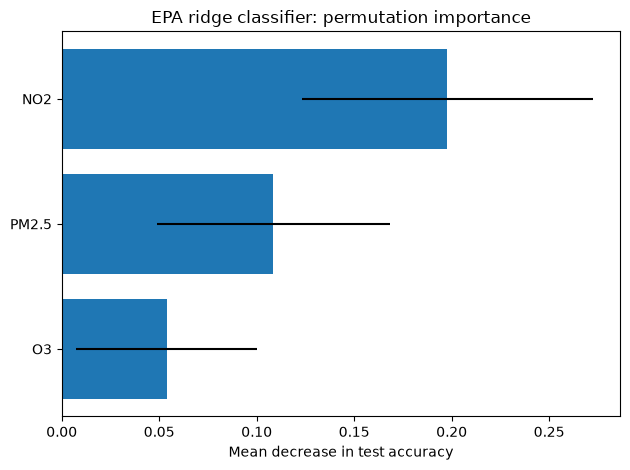

In [8]:
r = inspection.permutation_importance(model, X_test, y_test, n_repeats=30, scoring="accuracy", random_state=42)
order = r.importances_mean.argsort()
plt.barh(X.columns[order], r.importances_mean[order], xerr=r.importances_std[order])
plt.xlabel("Mean decrease in test accuracy")
plt.title("EPA ridge classifier: permutation importance")
plt.tight_layout()
plt.show()

In [9]:
df2 = pd.read_csv("../HW8/Waves_2023.txt", sep=r"\s+", na_values={"WVHT": 99, "DPD": 99, "APD": 99, "MWD": 999, "WTMP": 999})
df2 = df2[["DPD", "APD", "MWD", "WTMP", "WVHT"]].dropna()
X = df2[["DPD", "APD", "MWD", "WTMP"]]
y = df2["WVHT"]
X_train_val, X_test, y_train_val, y_test = model_selection.train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = model_selection.train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

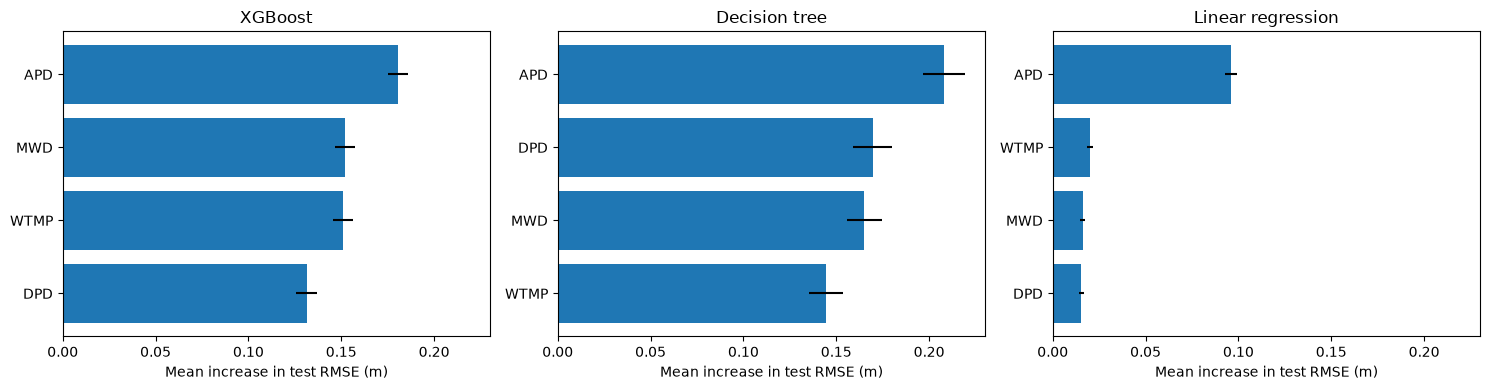

            Model  Test RMSE (m)
          XGBoost          0.302
    Decision tree          0.395
Linear regression          0.441


,XGBoost,Decision tree,Linear regression
DPD,0.131,0.170,0.015
APD,0.181,0.208,0.096
MWD,0.152,0.165,0.016
WTMP,0.151,0.145,0.020


In [10]:
models = {"XGBoost": XGBRegressor(n_estimators=46, random_state=42, n_jobs=4), "Decision tree": tree.DecisionTreeRegressor(random_state=42), "Linear regression": linear_model.LinearRegression()}
results = []
importance = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    results.append([name, metrics.root_mean_squared_error(y_test, model.predict(X_test))])
    r = inspection.permutation_importance(model, X_test, y_test, n_repeats=30, scoring="neg_root_mean_squared_error", random_state=42)
    importance[name] = pd.Series(r.importances_mean, index=X.columns)
    order = r.importances_mean.argsort()
    ax.barh(X.columns[order], r.importances_mean[order], xerr=r.importances_std[order])
    ax.set_title(name)
    ax.set_xlabel("Mean increase in test RMSE (m)")

plt.tight_layout()
plt.show()
print(pd.DataFrame(results, columns=["Model", "Test RMSE (m)"]).round(3).to_string(index=False))
pd.DataFrame(importance).round(3)


1. Single-pass backward PFI shuffles one feature and measures performance loss. 
2.Partial dependence varies one feature and averages predictions over other inputs. it is agnostic. 
3. Five:
- PFI: inspection.permutation_importance
- Partial dependence: inspection.partial_dependence
- Coefficients: linear_model.LinearRegression.coef_
- Gini importance: tree.DecisionTreeClassifier.feature_importances_ (after fitting)
- Feature selection: feature_selection.SequentialFeatureSelector